# Lezione 3 — Imparare dagli esempi: una macchina può scoprire da sola le regole?
**Machine Learning for the Humanities, 9 novembre**

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yuri-bizzoni/yuribizzoni/blob/main/ml-humanities/lessons/03_imparare_dagli_esempi_svm.ipynb)

**Laboratorio:** addestrare un classificatore testuale con scikit-learn. **Metodo:** Support Vector Machine (SVM).

Oggi mettiamo a confronto due modi di "insegnare" a un computer a riconoscere l'autore di un brano:
**scrivere noi le regole**, oppure **dargli degli esempi** e lasciare che le regole le trovi da solo.

### Obiettivi di apprendimento
1. capire la differenza tra programmazione a regole e apprendimento supervisionato;
2. rappresentare testi come **bag of words** e **TF-IDF**;
3. spiegare l'idea di una **SVM** (il confine con il margine più largo);
4. addestrare, valutare e usare un classificatore con `scikit-learn`;
5. guardare *dentro* il modello: quali parole ha imparato a usare?

In [ ]:
# ⚙️ CELLA DI PREPARAZIONE — eseguitela per prima (Shift+Invio) e non preoccupatevi del codice.
# Cerca la cartella "data" del corso; se non la trova (per esempio su Google Colab),
# scarica il materiale del corso da GitHub. Funziona anche senza internet, se avete la cartella.
from pathlib import Path
import subprocess

def trova_dati():
    for p in [Path("../data"), Path("data"), Path("ml-humanities/data"), Path("yuribizzoni/ml-humanities/data")]:
        if (p / "lessico_felicita.csv").exists():
            return p
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/yuri-bizzoni/yuribizzoni"], check=True)
    return Path("yuribizzoni/ml-humanities/data")

DATI = trova_dati()
print("Dati trovati in:", DATI.resolve())

Dati trovati in: /home/user/yuribizzoni/ml-humanities/data


In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split

passaggi = pd.read_csv(DATI / "passaggi_autori.csv")
X_train, X_test, y_train, y_test = train_test_split(
    passaggi["testo"], passaggi["autore"], test_size=0.25, random_state=0, stratify=passaggi["autore"])
print(len(X_train), "brani per addestrare,", len(X_test), "per verificare")

450 brani per addestrare, 150 per verificare


In [ ]:
passaggi.groupby("autore")["opera"].first()

autore
Collodi             Le avventure di Pinocchio
Deledda                      Dopo il divorzio
Di Giacomo                 Novelle napolitane
Manzoni                      I promessi sposi
Pirandello    Un cavallo nella luna (novelle)
Name: opera, dtype: str

## 1. Prima strada: scriviamo noi le regole
Un filologo potrebbe dire: *se compare "Pinocchio" è Collodi, se compare "Renzo" è Manzoni…* Proviamo.

In [ ]:
def regola(testo):
    t = testo.lower()
    if "pinocchio" in t or "geppetto" in t or "burattino" in t:
        return "Collodi"
    if "renzo" in t or "lucia" in t or "abbondio" in t:
        return "Manzoni"
    if "—" not in t:                  # senza dialoghi col trattino: proviamo Manzoni
        return "Manzoni"
    return "Deledda"                  # in mancanza di meglio...

previste = [regola(t) for t in X_test]
giuste = sum(p == v for p, v in zip(previste, y_test))
print(f"Regole a mano: {giuste}/{len(y_test)} giuste = {giuste / len(y_test):.0%}")

Regole a mano: 82/150 giuste = 55%


Funziona per due autori, molto meno per gli altri: per Pirandello o Di Giacomo non sappiamo bene che regola scrivere.
E ogni regola nuova va scritta, provata, corretta… a mano.

## 2. Seconda strada: imparare dagli esempi
Nell'**apprendimento supervisionato** diamo al computer molti esempi **già etichettati** (brano → autore) e un algoritmo
cerca da solo le regolarità che li distinguono. Ma prima i testi devono diventare numeri.

### Bag of words: il testo come sacchetto di parole
Ogni testo diventa una riga; ogni parola del vocabolario una colonna; nelle celle, quante volte la parola compare.
L'ordine delle parole si perde (da qui *sacchetto*).

In [ ]:
frasi = ["Che gioia il sabato del villaggio",
         "Il sabato porta gioia e poi noia",
         "La noia del lunedì"]
cv = CountVectorizer()
matrice = cv.fit_transform(frasi)
pd.DataFrame(matrice.toarray(), columns=cv.get_feature_names_out(), index=["frase 1", "frase 2", "frase 3"])

,che,del,gioia,il,la,lunedì,noia,poi,porta,sabato,villaggio
frase 1,1,1,1,1,0,0,0,0,0,1,1
frase 2,0,0,1,1,0,0,1,1,1,1,0
frase 3,0,1,0,0,1,1,1,0,0,0,0


### TF-IDF: pesare le parole
Le parole che compaiono **ovunque** (*il, del*) distinguono poco. **TF-IDF** dà più peso a una parola se è frequente
*in questo testo* (TF) ma rara *negli altri* (IDF).

In [ ]:
tfidf = TfidfVectorizer()
pd.DataFrame(tfidf.fit_transform(frasi).toarray(), columns=tfidf.get_feature_names_out(),
             index=["frase 1", "frase 2", "frase 3"]).round(2)

,che,del,gioia,il,la,lunedì,noia,poi,porta,sabato,villaggio
frase 1,0.48,0.37,0.37,0.37,0.00,0.00,0.00,0.00,0.00,0.37,0.48
frase 2,0.00,0.00,0.37,0.37,0.00,0.00,0.37,0.48,0.48,0.37,0.00
frase 3,0.00,0.43,0.00,0.00,0.56,0.56,0.43,0.00,0.00,0.00,0.00


## 3. L'idea della SVM
Immaginiamo ogni brano come un punto nello spazio. Una **Support Vector Machine** cerca il **confine** che separa le classi
lasciando il **margine più largo possibile** tra il confine e i punti più vicini (i *vettori di supporto*).
Un margine largo rende il modello più robusto su brani nuovi.

Visualizziamolo con due sole caratteristiche (trattini di dialogo e punti e virgola ogni 100 parole), Collodi contro Manzoni.
Con migliaia di parole succede la stessa cosa, ma in uno spazio con migliaia di dimensioni.

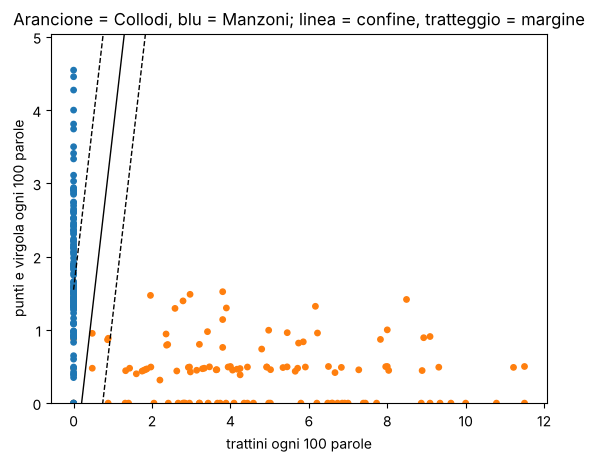

In [ ]:
due = passaggi[passaggi["autore"].isin(["Collodi", "Manzoni"])].copy()
n = due["testo"].str.split().str.len()
due["trattini"] = due["testo"].str.count("—") / n * 100
due["punto_virgola"] = due["testo"].str.count(";") / n * 100

svm2 = LinearSVC(C=1.0).fit(due[["trattini", "punto_virgola"]], due["autore"])

colori = due["autore"].map({"Collodi": "tab:orange", "Manzoni": "tab:blue"})
plt.scatter(due["trattini"], due["punto_virgola"], c=colori, s=15)
w, b = svm2.coef_[0], svm2.intercept_[0]
xs = np.linspace(0, due["trattini"].max(), 50)
for livello, stile in [(0, "-"), (-1, "--"), (1, "--")]:
    plt.plot(xs, (livello - b - w[0] * xs) / w[1], "k" + stile, lw=1)
plt.ylim(0, due["punto_virgola"].max() + 0.5)
plt.xlabel("trattini ogni 100 parole"); plt.ylabel("punti e virgola ogni 100 parole")
plt.title("Arancione = Collodi, blu = Manzoni; linea = confine, tratteggio = margine")
plt.show()

## 4. Il classificatore vero: TF-IDF + SVM su cinque autori
Una **pipeline** mette in fila i passaggi: prima il testo diventa un vettore TF-IDF, poi la SVM impara.
Addestriamo su 3/4 dei brani e verifichiamo sul quarto restante, che il modello **non ha mai visto**.

In [ ]:
modello = make_pipeline(TfidfVectorizer(), LinearSVC())
modello.fit(X_train, y_train)
accuratezza = modello.score(X_test, y_test)
print(f"Accuratezza sul test: {accuratezza:.1%}   (a caso: 20%)")

Accuratezza sul test: 100.0%   (a caso: 20%)


**Un risultato (quasi) perfetto. Troppo bello per essere vero?** Attenzione: nei nostri dati ogni autore è rappresentato
da **un solo libro**. Il modello potrebbe aver imparato a riconoscere *il libro* (i suoi personaggi, i suoi luoghi, la sua
edizione) più che *l'autore*. Ci torneremo l'11 novembre (*misurare il risultato*) e il 20 (*criticare*).

## 5. Che cosa ha imparato?
Una SVM lineare assegna un **peso** a ogni parola per ogni autore: le parole con il peso più alto sono gli indizi più forti.

In [ ]:
vettorizzatore = modello.named_steps["tfidfvectorizer"]
svm = modello.named_steps["linearsvc"]
vocabolario = vettorizzatore.get_feature_names_out()

indizi = {}
for i, autore in enumerate(svm.classes_):
    migliori = np.argsort(svm.coef_[i])[-12:][::-1]
    indizi[autore] = vocabolario[migliori]
pd.DataFrame(indizi)

,Collodi,Deledda,Di Giacomo,Manzoni,Pirandello
0,pinocchio,costantino,la,renzo,mimma
1,burattino,giovanna,si,lucia,lei
2,geppetto,zia,piccino,de,bax
3,fata,egli,vedova,che,crispucci
4,ragazzi,ed,le,don,naldi
5,babbo,giacobbe,tore,padre,bestia
6,assassini,brontu,mormorò,parte,su
7,mi,isidoro,innanzi,que,per
8,pesce,condannato,lui,abbondio,signor
9,povero,zio,pagliaccio,in,trockley


**Leggiamo la tabella da umanisti.** Ci sono i **nomi dei personaggi** (scontati: il modello "bara" un po'), ma anche indizi
di **lingua e grafia**: forme toscane o arcaiche (*ell'era, gli è*), il napoletano di Di Giacomo, le grafie d'epoca.
Il modello non sa *chi* è un autore: ha imparato **quali parole tendono a comparire** nei suoi brani.

## 6. Usare il modello su testi nuovi

In [ ]:
nuovi = [
    "Il burattino, tutto contento, si mise a ballare per la stanza.",
    "Quel ramo del lago, che volge a mezzogiorno, era tutto quieto; e la gente tornava a casa.",
    "La felicità? Una maschera, signori miei, che ci mettiamo per non vederci.",
    "Nel cortile, sotto la luna, la donna aspettava, e il vento portava odore di lentischio.",
]
for frase, autore in zip(nuovi, modello.predict(nuovi)):
    print(f"{autore:>11}  ←  {frase}")

    Collodi  ←  Il burattino, tutto contento, si mise a ballare per la stanza.
 Pirandello  ←  Quel ramo del lago, che volge a mezzogiorno, era tutto quieto; e la gente tornava a casa.
 Pirandello  ←  La felicità? Una maschera, signori miei, che ci mettiamo per non vederci.
 Di Giacomo  ←  Nel cortile, sotto la luna, la donna aspettava, e il vento portava odore di lentischio.


Guardate la seconda frase: è l'incipit dei *Promessi sposi*, appena ritoccato. Se il modello non lo attribuisce a Manzoni,
è perché non "conosce Manzoni": conosce i 90 brani manzoniani che ha visto, e in una frase così breve trova pochissimi indizi.
Più il testo è corto, più la decisione è fragile.

## 7. Una verifica più seria: la validazione incrociata
Un solo test può essere fortunato o sfortunato. La **validazione incrociata** (*cross-validation*) divide i dati in 5 parti,
addestra 5 volte lasciando fuori ogni volta una parte diversa, e fa la media.

In [ ]:
from sklearn.model_selection import cross_val_score
punteggi = cross_val_score(make_pipeline(TfidfVectorizer(), LinearSVC()), passaggi["testo"], passaggi["autore"], cv=5)
print("Accuratezza nei 5 giri:", punteggi.round(3), " media:", round(punteggi.mean(), 3))

Accuratezza nei 5 giri: [0.992 0.983 0.992 0.975 0.992]  media: 0.987


## Riepilogo
| Regole a mano | Apprendimento supervisionato |
|---|---|
| le scriviamo noi | le trova l'algoritmo dagli esempi |
| trasparenti ma faticose | veloci, ma vanno *interpretate* |
| non migliorano con più dati | migliorano con più (e migliori) esempi |

- **Bag of words / TF-IDF**: il testo come vettore di parole (l'ordine si perde).
- **SVM**: cerca il confine con il margine più largo.
- Valutare sempre su dati **mai visti** (train/test, cross-validation).

## Esercizi
Soluzioni in `solutions/03_imparare_dagli_esempi_svm_soluzioni.ipynb`.

**Esercizio 1 — Mettere alla prova il modello.** Scrivete tre frasi vostre "alla maniera" di tre autori diversi e una frase
moderna sulla felicità (per esempio un messaggio su WhatsApp). Che cosa risponde il modello? Che cosa fa con la frase moderna,
e perché non può rispondere "nessuno dei cinque"?

**Esercizio 2 — Lettere invece di parole.** Usate `TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4))`, cioè sequenze di
2–4 caratteri invece di parole intere. L'accuratezza sul test cambia? Perché le sequenze di caratteri potrebbero funzionare bene per lo stile?

**Esercizio 3 — Senza nomi propri.** Il modello usa molto i nomi dei personaggi. Togliete dal vocabolario una lista di nomi
(parametro `stop_words` di `TfidfVectorizer`) e riaddestrate. Quanto scende l'accuratezza? Che cosa ci dice su ciò che il modello "sa"?

In [ ]:
# Esercizio 1

In [ ]:
# Esercizio 2

In [ ]:
# Esercizio 3